# SCENIC+ ① — cisTopic topic modelling and DARs

The first block of the SCENIC+ pipeline (Bravo González-Blas *et al.*, *Nat Methods* 2023) turns a
single-cell ATAC fragment file into the **region sets** that the motif-enrichment block (cisTarget/DEM)
consumes: topics of co-accessible regions and differentially accessible regions (DARs) per cell type.
Upstream this is **pycisTopic**; `epione.scenic` reimplements it without Ray, Polars or Java:

| step | pycisTopic | Epione |
|---|---|---|
| fragment counts in regions | `create_cistopic_object_from_fragments` | `epi.scenic.cistopic_matrix` |
| LDA (collapsed Gibbs, `lda` backend) + model metrics | `run_cgs_models` | `epi.scenic.run_topic_models` |
| model selection | `evaluate_models` | `epi.scenic.evaluate_topic_models` |
| topic binarization (`otsu`, `ntop`, `li`, `yen`) | `binarize_topics` | `epi.scenic.binarize_topics` |
| imputed accessibility, normalization, HVF | `impute_accessibility`, `normalize_scores`, `find_highly_variable_features` | same names |
| DARs (Wilcoxon) | `find_diff_features` | `epi.scenic.find_diff_features` |

Every output is **bit-identical** to pycisTopic 2.0a0 run with the SCENIC+ 1.0 software stack — including the
stochastic Gibbs sampler, which consumes the same `numpy.random.RandomState` stream. The parity results
are tabulated at the end.

We use the dataset of the official SCENIC+ 1.0 tutorial: the 10x Multiome human cerebellum sample
(~3,000 nuclei) with the authors' cell-type annotation.

## Setup

In [1]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import pooch
import scanpy as sc
import matplotlib.pyplot as plt

import epione as epi

epi.pl.plot_set(dpi=80)
DATA = Path(os.environ.get("EPIONE_DATA_DIR", Path.home() / ".cache" / "epione")) / "scenic_cerebellum"
DATA.mkdir(parents=True, exist_ok=True)
N_JOBS = int(os.environ.get("SLURM_CPUS_PER_TASK", os.cpu_count() or 1))

└─ 🔬 Starting plot initialization...
  ├─ Apply Scanpy/matplotlib settings
  ├─ Custom font setup
  ├─ Suppress warnings
  ├─ 
___________      .__                      
\_   _____/_____ |__| ____   ____   ____  
 |    __)_\____ \|  |/  _ \ /    \_/ __ \ 
 |        \  |_> >  (  <_> )   |  \  ___/ 
/_______  /   __/|__|\____/|___|  /\___  >
        \/|__|                  \/     \/ 

  ├─ 🔖 Version: 0.0.1rc1   📚 Tutorials: https://epione.readthedocs.io/
└─ ✅ plot_set complete.



## Download the data

Fragments and peaks of the 10x Genomics *human_brain_3k* Multiome sample, the cell annotation shipped with
pycisTopic, and the ENCODE hg38 blacklist v2 (copy distributed with pycisTopic). Downloads are cached and
verified by SHA-256; the fragment file is 1.6 GB.

In [2]:
TENX = "https://cf.10xgenomics.com/samples/cell-arc/1.0.0/human_brain_3k/"
PCT = "https://raw.githubusercontent.com/aertslab/pycisTopic/polars/"
files = {
    "human_brain_3k_atac_fragments.tsv.gz": (TENX + "human_brain_3k_atac_fragments.tsv.gz",
        "dd3513999f458e97fdf635cc0641df337c734119b122074da9dcfda17af17226"),
    "human_brain_3k_atac_peaks.bed": (TENX + "human_brain_3k_atac_peaks.bed",
        "8ea9a8dbd60060a9f1a64fd86bfd0ccf4eb72be4862d3697175156361ad2d9f6"),
    "cell_data_human_cerebellum.tsv": (PCT + "data/cell_data_human_cerebellum.tsv",
        "e762f44f1a6523614c019419bf8971da536bba72ca5a0322d0e1b215f863a56c"),
    "hg38-blacklist.v2.bed": (PCT + "blacklist/hg38-blacklist.v2.bed",
        "31c69342df43bbc19dd8ef2886611a8150cb53e90f341de14d30e742c9251737"),
}
paths = {name: Path(pooch.retrieve(url, known_hash="sha256:" + sha, fname=name, path=DATA, progressbar=False))
         for name, (url, sha) in files.items()}
for name, p in paths.items():
    print(f"{name:40s} {p.stat().st_size / 1e6:9.1f} MB")

human_brain_3k_atac_fragments.tsv.gz        1647.7 MB
human_brain_3k_atac_peaks.bed                  2.1 MB
cell_data_human_cerebellum.tsv                 0.3 MB
hg38-blacklist.v2.bed                          0.0 MB


In [3]:
cell_data = pd.read_csv(paths["cell_data_human_cerebellum.tsv"], sep="\t", index_col=0)
cell_data["barcode"] = [c.rsplit("-", 1)[0] for c in cell_data.index]   # drop the sample suffix
print(cell_data.shape)
cell_data["Seurat_cell_type"].value_counts()

(2392, 10)


Seurat_cell_type
MOL          819
BG           316
NFOL         306
OPC          185
GC           142
INH_VIP      122
INH_SST       81
MGL           77
MG            73
COP           72
GP            47
INH_SNCG      46
AST           37
PURK          30
INH_PVALB     20
ENDO          19
Name: count, dtype: int64

## Fragment counts in peaks

`cistopic_matrix` streams the fragment file and counts, for every annotated barcode and peak, the
fragments overlapping the peak (any overlap, 0-based half-open coordinates). Blacklisted peaks and peaks
without counts are removed. The result is a cells × regions AnnData with pycisTopic's QC columns; cell
names get the `-<project>` suffix pycisTopic appends (`split_pattern="-"`), so they match the annotation.

In [4]:
import time
t0 = time.time()
peaks = pd.read_csv(paths["human_brain_3k_atac_peaks.bed"], sep="\t", header=None, comment="#",
                    usecols=[0, 1, 2], names=["Chromosome", "Start", "End"])
acc = epi.scenic.cistopic_matrix(
    paths["human_brain_3k_atac_fragments.tsv.gz"], peaks,
    barcodes=cell_data["barcode"].tolist(),
    blacklist=paths["hg38-blacklist.v2.bed"],
    project="10x_multiome_brain", split_pattern="-",
)
print(f"{time.time() - t0:.0f} s")
acc.obs = acc.obs.join(cell_data.drop(columns="barcode"))
acc

  └─ [scenic.topics] counting fragments in regions


  └─ [scenic.topics] 152,844,735 fragments read, 20,189,727 non-zero region × cell counts


45 s


AnnData object with n_obs × n_vars = 2392 × 86022
    obs: 'cisTopic_nr_frag', 'cisTopic_log_nr_frag', 'cisTopic_nr_acc', 'cisTopic_log_nr_acc', 'sample_id', 'Unique_nr_frag', 'barcode', 'VSN_cell_type', 'VSN_leiden_res0.3', 'VSN_leiden_res0.6', 'VSN_leiden_res0.9', 'VSN_leiden_res1.2', 'VSN_sample_id', 'Seurat_leiden_res0.6', 'Seurat_leiden_res1.2', 'Seurat_cell_type'
    var: 'Chromosome', 'Start', 'End', 'Width', 'cisTopic_nr_frag', 'cisTopic_log_nr_frag', 'cisTopic_nr_acc', 'cisTopic_log_nr_acc'
    uns: 'cistopic'
    layers: 'binary'

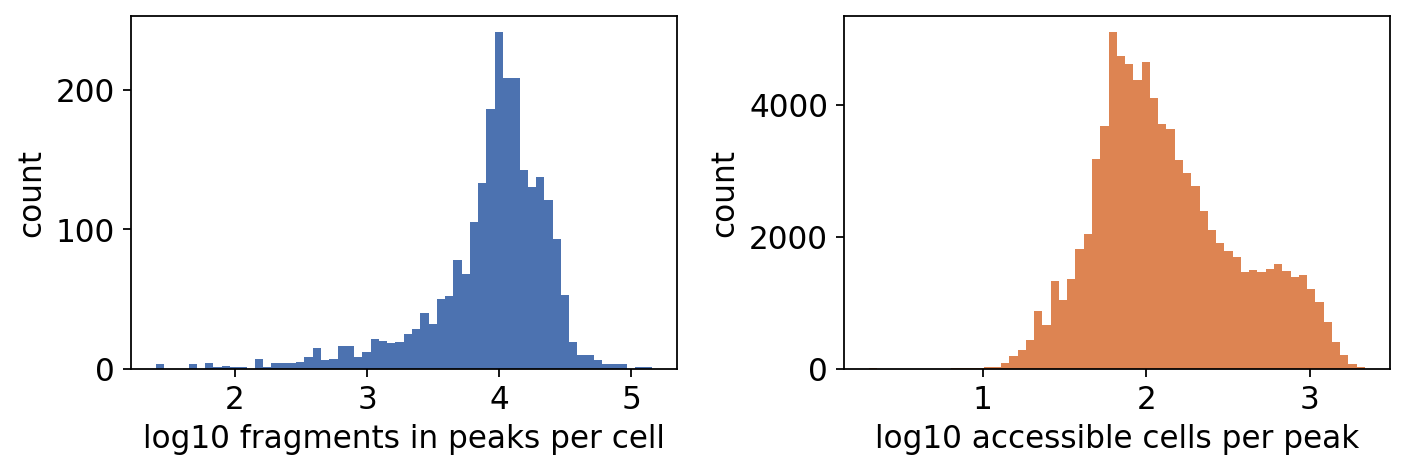

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
axes[0].hist(acc.obs["cisTopic_log_nr_frag"], bins=60, color="#4C72B0")
axes[0].set_xlabel("log10 fragments in peaks per cell")
axes[1].hist(acc.var["cisTopic_log_nr_acc"], bins=60, color="#DD8452")
axes[1].set_xlabel("log10 accessible cells per peak")
for ax in axes:
    ax.set_ylabel("count")
plt.tight_layout()

## Topic models

`run_topic_models` fits one LDA model per number of topics with the collapsed Gibbs sampler of the `lda`
package, using pycisTopic's defaults (`alpha = 50 / K`, `eta = 0.1`, `random_state = 555`). Models run as
threads; each one is single-threaded and deterministic, so the result does not depend on `n_jobs`.
We use 150 sweeps (pycisTopic's default; the SCENIC+ tutorial uses 500).

In [6]:
t0 = time.time()
models = epi.scenic.run_topic_models(acc, n_topics=[10, 20, 30, 40], n_iter=150, n_jobs=N_JOBS)
print(f"{time.time() - t0:.0f} s")
pd.concat([m.metrics.assign(n_topics=m.n_topic) for m in models]).set_index("n_topics")

  └─ [scenic.topics] running model with 10 topics


  └─ [scenic.topics] running model with 20 topics


  └─ [scenic.topics] running model with 30 topics


  └─ [scenic.topics] running model with 40 topics


  └─ [scenic.topics] model with 10 topics done (250.4 s)


  └─ [scenic.topics] model with 20 topics done (303.7 s)


  └─ [scenic.topics] model with 30 topics done (359.5 s)


  └─ [scenic.topics] model with 40 topics done (427.6 s)


430 s


,Arun_2010,Cao_Juan_2009,Mimno_2011,loglikelihood
n_topics,,,,
10,0.036001,0.212151,-0.461989,-1.825854e+07
20,0.031199,0.152860,-0.372328,-8.351737e+06
30,0.106577,0.124011,-0.418218,-6.695518e+06
40,0.192387,0.111844,-0.348035,-7.925224e+06


selected: 20 topics


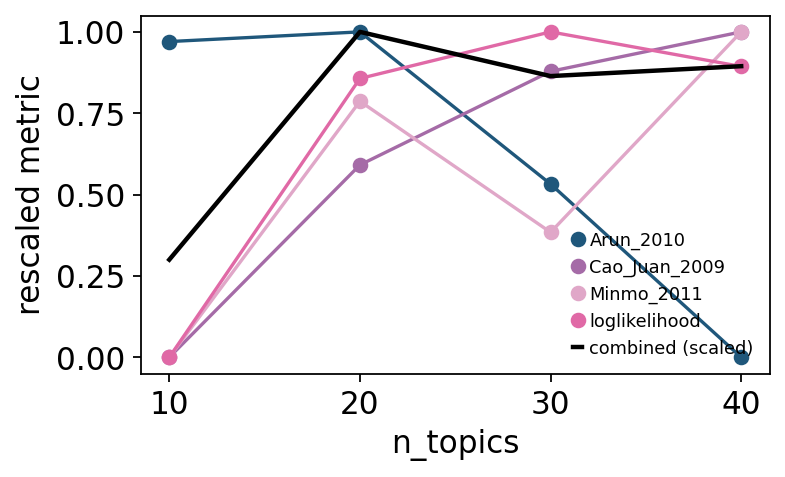

In [7]:
model, table = epi.scenic.evaluate_topic_models(models, return_metrics=True)
print("selected:", model.n_topic, "topics")
ax = table.drop(columns="combined").plot(marker="o", figsize=(5, 3.2))
table["combined"].div(table["combined"].max()).plot(ax=ax, color="k", lw=2, label="combined (scaled)")
ax.set_ylabel("rescaled metric"); ax.legend(fontsize=8, frameon=False)
plt.tight_layout()

`evaluate_topic_models` rescales each metric to [0, 1] across models — Mimno 2011 coherence and
log-likelihood (higher is better), Arun 2010 and Cao-Juan 2009 (inverted) — and picks the model with the
largest sum, as pycisTopic does. The cell-topic matrix is stored in `obsm["X_topic"]` and can be used like
any embedding.

computing neighbors


    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:10)


computing UMAP


    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:00:05)


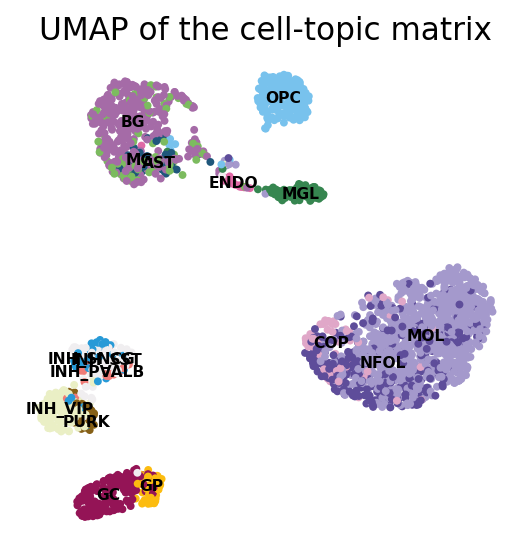

In [8]:
epi.scenic.add_topic_model(acc, model)
sc.pp.neighbors(acc, use_rep="X_topic", n_neighbors=15, random_state=0)
sc.tl.umap(acc, random_state=0)
sc.pl.umap(acc, color="Seurat_cell_type", legend_loc="on data", legend_fontsize=7, frameon=False,
           title="UMAP of the cell-topic matrix")

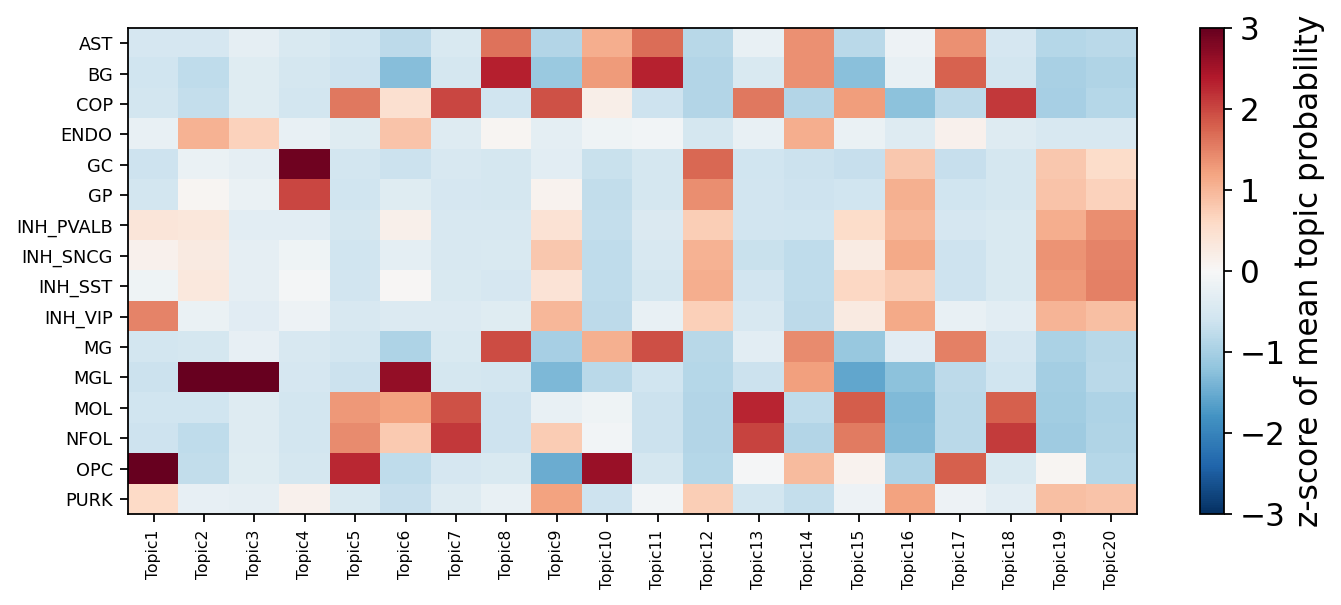

In [9]:
ct = pd.DataFrame(acc.obsm["X_topic"], index=acc.obs_names, columns=acc.uns["topic"]["topics"])
mean = ct.groupby(acc.obs["Seurat_cell_type"]).mean()
z = (mean - mean.mean()) / mean.std()
fig, ax = plt.subplots(figsize=(9, 4))
im = ax.imshow(z.values, aspect="auto", cmap="RdBu_r", vmin=-3, vmax=3)
ax.set_xticks(range(z.shape[1]), z.columns, rotation=90, fontsize=7)
ax.set_yticks(range(z.shape[0]), z.index, fontsize=8)
plt.colorbar(im, ax=ax, label="z-score of mean topic probability")
plt.tight_layout()

## Binarize topics

Topic-region distributions are first smoothed (regions likely in many topics are down-weighted) and then
thresholded per topic: Otsu's method, or the top `ntop` regions. Cell-topic distributions are binarized
with Li's minimum cross-entropy threshold.

In [10]:
region_otsu = epi.scenic.binarize_topics(model, method="otsu")
region_top3k = epi.scenic.binarize_topics(model, method="ntop", ntop=3000)
cell_li = epi.scenic.binarize_topics(model, target="cell", method="li", nbins=100)
pd.DataFrame({"regions (otsu)": {t: len(v) for t, v in region_otsu.items()},
              "regions (top 3k)": {t: len(v) for t, v in region_top3k.items()},
              "cells (li)": {t: len(v) for t, v in cell_li.items()}}).T

,Topic1,Topic2,Topic3,Topic4,Topic5,Topic6,Topic7,Topic8,Topic9,Topic10,Topic11,Topic12,Topic13,Topic14,Topic15,Topic16,Topic17,Topic18,Topic19,Topic20
regions (otsu),4268,2116,5201,8702,2496,1759,3865,5541,3564,3363,6540,5800,2378,4437,1850,4405,4065,3116,3127,4572
regions (top 3k),3000,3000,3000,3000,3000,3000,3000,3000,3000,3000,3000,3000,3000,3000,3000,3000,3000,3000,3000,3000
cells (li),261,80,81,189,1311,1256,1191,422,971,568,425,479,1189,693,1222,817,601,1168,650,487


In [11]:
region_otsu["Topic1"].head()

,Topic1
chr17:66964203-66966155,0.004112
chr2:5691287-5693758,0.003596
chr7:49773205-49776257,0.003547
chr8:55100921-55103396,0.003518
chr10:104638768-104643246,0.003453


## Imputed accessibility and DARs

The imputed accessibility of region *r* in cell *c* is `topic_region[r] · cell_topic[:, c]`, scaled by
10⁶ and truncated to an integer. After library-size normalization, highly variable regions are tested
cell type versus rest with a Wilcoxon rank-sum test (BH-adjusted p ≤ 0.05, log2 fold change ≥ log2 1.5).
Epione ranks each region once over all cells and reads every contrast's rank sum from that ranking.

In [12]:
t0 = time.time()
imputed = epi.scenic.impute_accessibility(model, scale_factor=10**6)
normalized = epi.scenic.normalize_scores(imputed, scale_factor=10**4)
hvr = epi.scenic.find_highly_variable_features(normalized, min_disp=0.05, min_mean=0.0125, max_mean=3,
                                               n_bins=20)
del normalized
dars = epi.scenic.find_diff_features(imputed, acc.obs["Seurat_cell_type"], var_features=hvr,
                                     adjpval_thr=0.05, log2fc_thr=np.log2(1.5))
print(imputed, f"\n{len(hvr):,} variable regions, {time.time() - t0:.0f} s")
pd.Series({k: len(v) for k, v in dars.items()}, name="DARs").to_frame().T

ImputedFeatures(features=86017, cells=2392, dtype=int32) 
40,560 variable regions, 15 s


,AST,BG,COP,ENDO,GC,GP,INH_PVALB,INH_SNCG,INH_SST,INH_VIP,MG,MGL,MOL,NFOL,OPC,PURK
DARs,16059,17072,5534,5532,17168,17037,13162,14207,13927,15800,16151,6894,7372,6199,9859,17115


In [13]:
dars["PURK"].head()

,Log2FC,Adjusted_pval,Contrast
chr3:120646872-120647023,2.180215,8.432435e-13,PURK
chr9:123106755-123106832,2.170135,7.505781e-13,PURK
chr9:113675622-113675806,2.154823,7.028799e-13,PURK
chr1:10449989-10450185,2.147932,1.289713e-12,PURK
chr2:39871448-39871547,2.147443,1.480755e-12,PURK


## Region sets for the motif-enrichment block

The binarized topics and the DARs are the region sets that cisTarget and DEM score for motif enrichment
(SCENIC+ block ②). `write_region_sets` saves them as sorted BED files, the layout pycistarget reads.

In [14]:
region_sets = {
    "Topics_otsu": {t: df.index for t, df in region_otsu.items()},
    "Topics_top_3k": {t: df.index for t, df in region_top3k.items()},
    "DARs_cell_type": {ct: df.index for ct, df in dars.items() if len(df)},
}
epi.scenic.write_region_sets(DATA / "region_sets", region_sets)
sorted(p.relative_to(DATA).as_posix() for p in (DATA / "region_sets").glob("*/*.bed"))[:5]

['region_sets/DARs_cell_type/AST.bed',
 'region_sets/DARs_cell_type/BG.bed',
 'region_sets/DARs_cell_type/COP.bed',
 'region_sets/DARs_cell_type/ENDO.bed',
 'region_sets/DARs_cell_type/GC.bed']

## Parity with pycisTopic

The same functions were run on the SCENIC+ 1.0 tutorial setup (436,234 consensus peaks from per-cell-type
MACS2 calls, LDA with 500 sweeps for K = 10, 20, 30, 40) and compared with pycisTopic 2.0a0 run with the
pinned SCENIC+ 1.0 stack (numpy 1.26.4, scipy 1.12, pandas 1.5.3, `lda` 3.0.0, `PYTHONHASHSEED=0`).
The reference outputs are produced outside this repository; the thresholds were registered before the
comparison (`tests/parity/scenic_topics/MANIFEST.md`).

| output | pycisTopic call | result |
|---|---|---|
| fragment counts, region and cell order, QC columns | `create_cistopic_object_from_fragments` | identical (32.7 M non-zeros) |
| topic assignments, `cell_topic`, `topic_region` (4 models) | `run_cgs_models` | identical (max abs err 0) |
| Arun 2010, Cao Juan 2009, Mimno 2011, log-likelihood, marginal topic distribution | `run_cgs_models` | identical (max rel err 0) |
| selected model | `evaluate_models` | K = 20 in both |
| binarized topics (`ntop`, `otsu`, cell `li`): features, order, scores | `binarize_topics` | identical |
| imputed accessibility (1.04 × 10⁹ int32 values) | `impute_accessibility` | identical |
| normalized accessibility, 70,220 variable regions | `normalize_scores`, `find_highly_variable_features` | identical |
| DARs of 16 cell types: regions, order, `Log2FC`, `Adjusted_pval` | `find_diff_features` | identical |
| 56 region-set BED files | — | byte-identical |

pycisTopic's numbers depend on numpy internals that changed after numpy 1.26 and that differ between
CPUs: the order `np.argsort` gives to tied values, the SVML `log`/`log1p`/`log10` kernels and the
buffered pairwise `np.sum`. `epione.scenic` reproduces numpy 1.26 on AVX-512 CPUs (the reference
platform) on any machine; pass `compat="native"` to use the installed numpy instead.

Timing on the same node (pycisTopic baseline from the reference run):

| stage | pycisTopic | Epione |
|---|---|---|
| fragment counts | 161 s | 53–68 s |
| LDA, 4 models × 500 sweeps, 4 cores | 10,061 s | 3,086 s |
| LDA, one sweep at K = 10 / 20 / 40, 1 core | 5.2 / 12.1 / 21.0 s | 2.0 / 2.4 / 4.0 s |
| binarize topics | 8.4 s | 2 s |
| DARs, 16 contrasts, 4 cores | 120 s | 20 s |